# Assignment 4: Text and Sequence Data
### Learned embedding layer vs. pretrained GloVe embeddings on IMDB with very little training data

**Goal.** Re-run the IMDB embedding example with these changes from the assignment:

| # | Requirement | Where it is set |
|---|---|---|
| 1 | Cut off reviews after **150 words** | `MAX_LEN = 150` |
| 2 | Restrict training samples to **100** | `N_TRAIN_REQUIRED = 100` |
| 3 | Validate on **10,000** samples | `N_VAL = 10_000` |
| 4 | Consider only the **top 10,000 words** | `MAX_TOKENS = 10_000` |
| 5 | Compare a **learned embedding layer** with a **pretrained word embedding** (GloVe), then vary the number of training samples to find where the learned embedding starts doing better | Sections 6, 8 and 9 |

**Model.** Every experiment uses the same sequence model from the course (a bidirectional LSTM on top of an embedding). Only the embedding changes:

* **Learned embedding:** `Embedding` layer with random initial weights, trained from scratch on the task.
* **GloVe (frozen):** the embedding layer is loaded with 100-d GloVe vectors (trained on 6B tokens of Wikipedia + Gigaword) and frozen.
* **GloVe (fine-tuned):** an extra "improve performance" variant. It starts from GloVe and lets backprop adjust the vectors.

**Before you run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
No files need to be uploaded. The notebook downloads IMDB (~84 MB) and GloVe (~860 MB zip) itself.
The full experiment takes about **30–45 min on a T4 GPU**. Results are saved after every run, so if Colab disconnects you can re-run the notebook and it skips runs that are already done.

**RAM.** Peak usage is roughly 2–3 GB of the ~12 GB available. The main savings are:
GloVe is streamed straight out of the zip and only the ~10k vectors we need are kept (the 400k-word table is never loaded),
reviews are stored as compact `int32` arrays and the raw text is deleted,
and the Keras session is cleared after every model.

## 1. Setup

In [1]:
import os, gc, io, re, time, string, zipfile, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import psutil

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)   # do not grab all GPU memory up front
    except RuntimeError:
        pass
print("GPU:", gpus if gpus else "NONE. Switch to Runtime > Change runtime type > T4 GPU (CPU works but is much slower)")

def ram():
    vm = psutil.virtual_memory()
    return f"RAM used {vm.used / 1e9:.2f} GB of {vm.total / 1e9:.2f} GB"
print(ram())

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
RAM used 1.29 GB of 13.61 GB


## 2. Configuration
All assignment settings are in one place. `TRAIN_SIZES` is the grid used to find the crossover point.
Small training sets give noisy results (100 reviews is tiny), so every size up to `SMALL_CUTOFF` is repeated with 3 seeds and averaged.

In [2]:
# ---- Assignment requirements ----
MAX_LEN          = 150      # (1) cut off reviews after 150 words
N_TRAIN_REQUIRED = 100      # (2) training samples for the required experiment
N_VAL            = 10_000   # (3) validation samples
MAX_TOKENS       = 10_000   # (4) top 10,000 words (includes the padding and OOV indices)
EMBED_DIM        = 100      # same size as the GloVe vectors (glove.6B.100d) for a fair comparison

# ---- Experiment grid (5) ----
TRAIN_SIZES  = [100, 200, 500, 1000, 2000, 5000, 10000, 15000]  # 15,000 = every training review not used for validation
SEEDS_SMALL  = [42, 7, 2024]   # repeated runs for small sizes (noisy)
SEEDS_LARGE  = [42]            # one run is enough for large sizes
SMALL_CUTOFF = 2000
MODEL_KINDS  = ["learned", "glove_frozen", "glove_finetuned"]   # drop "glove_finetuned" to save ~1/3 of the time

# ---- Training ----
MAX_EPOCHS = 30
PATIENCE   = 5          # early stopping on validation accuracy
BATCH_SIZE = 32
SPLIT_SEED = 1337       # fixes the train/validation split

# ---- Paths ----
DATA_DIR    = "/content/data"
RESULTS_CSV = "/content/a4_results.csv"
FIG_DIR     = "/content"
os.makedirs(DATA_DIR, exist_ok=True)

LABELS = {"learned": "Learned embedding", "glove_frozen": "GloVe (frozen)", "glove_finetuned": "GloVe (fine-tuned)"}

## 3. Download the raw IMDB data
This is the raw text version (`aclImdb`) used in the textbook example: 25,000 training and 25,000 test reviews, half positive and half negative.
Only the `train/pos`, `train/neg`, `test/pos` and `test/neg` folders are extracted. The 50,000 unlabeled reviews are skipped.

In [3]:
IMDB_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
imdb_dir = os.path.join(DATA_DIR, "aclImdb")

if not os.path.isdir(os.path.join(imdb_dir, "test", "neg")):
    tar_path = keras.utils.get_file("aclImdb_v1.tar.gz", IMDB_URL, cache_dir=DATA_DIR, cache_subdir="")
    keep = re.compile(r"^aclImdb/(train|test)/(pos|neg)/[^/]+\.txt$")
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar:                                   # stream member by member (low RAM)
            if m.isfile() and keep.match(m.name):
                tar.extract(m, DATA_DIR)
    os.remove(tar_path)                                 # free disk space
print("IMDB ready at", imdb_dir)

84125825/84125825 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step


/tmp/ipykernel_831/4119177607.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(m, DATA_DIR)


IMDB ready at /content/data/aclImdb


## 4. Load the text and split it into train pool, validation and test
* The 25,000 training reviews are shuffled once with a fixed seed. The first **10,000 are the validation set**, and the remaining **15,000 are the pool** that training samples are drawn from.
* The official 25,000-review **test set** is used only for a final, untouched check of each model.
* Training samples are drawn **stratified** (half positive, half negative). With only 100 reviews, an unlucky 40/60 split would otherwise add noise. For a given seed, both models train on **exactly the same reviews**, so the comparison is paired.

In [4]:
def load_split(split):
    texts, labels = [], []
    for label_name, label in (("neg", 0), ("pos", 1)):
        folder = os.path.join(imdb_dir, split, label_name)
        for fname in sorted(os.listdir(folder)):
            if fname.endswith(".txt"):
                with open(os.path.join(folder, fname), encoding="utf-8") as f:
                    texts.append(f.read())
                labels.append(label)
    return texts, np.array(labels, dtype="int32")

train_texts, train_labels = load_split("train")
test_texts,  test_labels  = load_split("test")

rng = np.random.default_rng(SPLIT_SEED)
order = rng.permutation(len(train_texts))
val_idx, pool_idx = order[:N_VAL], order[N_VAL:]

val_texts   = [train_texts[i] for i in val_idx];   val_y  = train_labels[val_idx]
pool_texts  = [train_texts[i] for i in pool_idx];  pool_y = train_labels[pool_idx]
test_y      = test_labels
del train_texts, train_labels, order; gc.collect()

print(f"Training pool: {len(pool_texts):,} | Validation: {len(val_texts):,} | Test: {len(test_texts):,}")
print(f"Positive share  pool {pool_y.mean():.3f} | val {val_y.mean():.3f} | test {test_y.mean():.3f}")
print(ram())

Training pool: 15,000 | Validation: 10,000 | Test: 25,000
Positive share  pool 0.497 | val 0.504 | test 0.500
RAM used 1.96 GB of 13.61 GB


## 5. Vectorize: standardize, tokenize, index, truncate to 150 words
This follows the course's text-vectorization template with the Keras `TextVectorization` layer:
1. **Standardize:** lowercase, strip the `<br />` HTML tags common in IMDB reviews, and remove punctuation.
2. **Tokenize:** split on whitespace (word-level tokens, because this is a sequence model).
3. **Index:** keep the top 10,000 tokens. Index 0 is padding (and is masked), and index 1 is the out-of-vocabulary token `[UNK]`.
4. **Cut off / pad** every review to exactly **150 tokens**. Longer reviews are truncated and shorter ones are zero-padded at the end.

The vocabulary is built from the 15,000-review training pool only (text only, no labels), so validation and test text never leak into it. The same vocabulary is used for every training size, which keeps the comparison fair.
The vectorized data is stored as `int32` (about 60 MB in total) and the raw strings are deleted.

In [5]:
def custom_standardization(x):
    x = tf.strings.lower(x)
    x = tf.strings.regex_replace(x, r"<br\s*/?>", " ")
    return tf.strings.regex_replace(x, f"[{re.escape(string.punctuation)}]", "")

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LEN,
    standardize=custom_standardization,
)
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(pool_texts).batch(1024))
vocab = [str(w) for w in vectorizer.get_vocabulary()]
VOCAB_SIZE = len(vocab)

def vectorize(texts, chunk=2048):
    out = np.zeros((len(texts), MAX_LEN), dtype="int32")
    for i in range(0, len(texts), chunk):
        out[i:i + chunk] = vectorizer(tf.constant(texts[i:i + chunk])).numpy()
    return out

pool_x = vectorize(pool_texts)
val_x  = vectorize(val_texts)
test_x = vectorize(test_texts)

# How many reviews does the 150-word cutoff actually shorten?
lengths = np.array([len(custom_standardization(t).numpy().split()) for t in pool_texts[:2000]])
print(f"Vocabulary size: {VOCAB_SIZE:,}   (first tokens: {vocab[:8]})")
print(f"Median review length: {np.median(lengths):.0f} words; {np.mean(lengths > MAX_LEN):.0%} of reviews are cut at {MAX_LEN}")
print(f"OOV share of tokens in validation set: {(val_x == 1).sum() / (val_x > 0).sum():.1%}")

del pool_texts, val_texts, test_texts, lengths, vectorizer; gc.collect()
print("Arrays:", pool_x.shape, val_x.shape, test_x.shape, "|", ram())

Vocabulary size: 10,000   (first tokens: ['', '[UNK]', 'the', 'a', 'and', 'of', 'to', 'is'])
Median review length: 173 words; 60% of reviews are cut at 150
OOV share of tokens in validation set: 6.2%
Arrays: (15000, 150) (10000, 150) (25000, 150) | RAM used 2.20 GB of 13.61 GB


## 6. Pretrained word embedding: GloVe 6B, 100 dimensions
GloVe vectors are computed from word co-occurrence statistics over 6 billion tokens, so they already encode useful semantic structure (for example, *good* sits close to *decent*).

**RAM-safe loading.** The usual approach builds a dictionary of all 400,000 GloVe words. Here the 100-d file is read **line by line directly from inside the zip**, and only rows for words in our 10,000-word vocabulary are kept. The result is a `(10,000 × 100)` `float32` matrix of about 4 MB.
Rows 0 (padding) and 1 (OOV) stay at zero, and so do vocabulary words that GloVe does not know.

*Optional:* if you already have `glove.6B.100d.txt`, upload it to `/content/data/` and the download is skipped.

In [6]:
GLOVE_URLS = [
    "https://nlp.stanford.edu/data/glove.6B.zip",                               # official
    "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip",      # mirror if Stanford is slow or down
]
glove_txt = os.path.join(DATA_DIR, "glove.6B.100d.txt")
glove_zip = os.path.join(DATA_DIR, "glove.6B.zip")
glove_npy = os.path.join(DATA_DIR, f"glove_matrix_{VOCAB_SIZE}.npy")

def glove_lines():
    if os.path.exists(glove_txt):
        with open(glove_txt, encoding="utf-8") as f:
            yield from f
    else:
        with zipfile.ZipFile(glove_zip) as zf, zf.open("glove.6B.100d.txt") as raw:
            yield from io.TextIOWrapper(raw, encoding="utf-8")

if os.path.exists(glove_npy):
    embedding_matrix = np.load(glove_npy)
else:
    if not os.path.exists(glove_txt) and not os.path.exists(glove_zip):
        for url in GLOVE_URLS:
            try:
                keras.utils.get_file("glove.6B.zip", url, cache_dir=DATA_DIR, cache_subdir="")
                break
            except Exception as e:
                print("Download failed from", url, "->", e)
        else:
            raise RuntimeError("Could not download GloVe. Upload glove.6B.100d.txt to /content/data and re-run this cell.")

    word_index = {w: i for i, w in enumerate(vocab)}
    embedding_matrix = np.zeros((VOCAB_SIZE, EMBED_DIM), dtype="float32")
    for line in glove_lines():
        word, rest = line.rstrip().split(" ", 1)
        i = word_index.get(word)
        if i is not None and i > 1:
            embedding_matrix[i] = np.asarray(rest.split(" "), dtype="float32")
    np.save(glove_npy, embedding_matrix)
    if os.path.exists(glove_zip):
        os.remove(glove_zip)            # about 860 MB of disk freed; the small .npy cache is kept

covered = int((np.abs(embedding_matrix).sum(axis=1) > 0).sum())
print(f"GloVe vectors found for {covered:,} of {VOCAB_SIZE - 2:,} vocabulary words ({covered / (VOCAB_SIZE - 2):.1%})")
print(ram())

Download failed from https://nlp.stanford.edu/data/glove.6B.zip -> URL fetch failure on https://nlp.stanford.edu/data/glove.6B.zip: None -- [Errno 113] No route to host
862182753/862182753 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
GloVe vectors found for 9,891 of 9,998 vocabulary words (98.9%)
RAM used 2.34 GB of 13.61 GB


## 7. Model and experiment runner
**Architecture** (identical for all three variants; only the embedding differs):

`Input(150 ints) → Embedding(10,000 × 100, mask_zero=True) → Bidirectional(LSTM(32)) → Dropout(0.5) → Dense(1, sigmoid)`

* `mask_zero=True` tells the LSTM to skip padding positions, so short reviews are not followed by many "empty" steps that wash out the hidden state (the masking idea from the Word Embeddings module).
* For GloVe (frozen), the embedding layer is set to `trainable=False`, as in the course's pretrained-embedding example. Otherwise backprop would overwrite the pretrained knowledge, which matters most with only 100 examples.
* **Early stopping** is driven by validation accuracy (patience 5), and the weights from the **best epoch** are restored before scoring.
* Each run records the best validation accuracy, the test accuracy of those weights, and the training time. It is appended to `a4_results.csv` right away, so a restart resumes where it stopped.
* After each run, `clear_session()` + `gc.collect()` releases the model, keeping RAM flat across the 50+ runs.

In [7]:
def build_model(kind):
    inputs = keras.Input(shape=(MAX_LEN,), dtype="int32")
    embedding = layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True, name="embedding")
    x = embedding(inputs)
    x = layers.Bidirectional(layers.LSTM(32))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    if kind in ("glove_frozen", "glove_finetuned"):
        embedding.set_weights([embedding_matrix])
        embedding.trainable = (kind == "glove_finetuned")
    model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])
    return model

class KeepBestWeights(keras.callbacks.Callback):
    # Remember the weights of the epoch with the highest val_accuracy and restore them when training ends
    def on_train_begin(self, logs=None):
        self.best, self.weights = -1.0, None
    def on_epoch_end(self, epoch, logs=None):
        if logs["val_accuracy"] > self.best:
            self.best, self.weights = logs["val_accuracy"], self.model.get_weights()
    def on_train_end(self, logs=None):
        if self.weights is not None:
            self.model.set_weights(self.weights)

pos_pool, neg_pool = np.where(pool_y == 1)[0], np.where(pool_y == 0)[0]

def sample_train(n, seed):
    # Stratified sample of n reviews from the pool (the same reviews for every model at a given seed)
    if n >= len(pool_y):
        idx = np.random.default_rng(seed).permutation(len(pool_y))
    else:
        r = np.random.default_rng(seed)
        idx = np.concatenate([r.choice(pos_pool, n // 2, replace=False),
                              r.choice(neg_pool, n - n // 2, replace=False)])
        r.shuffle(idx)
    return pool_x[idx], pool_y[idx]

histories = {}   # learning curves of the required 100-sample runs

def run_one(kind, n, seed):
    keras.backend.clear_session(); gc.collect()
    keras.utils.set_random_seed(seed)
    x_tr, y_tr = sample_train(n, seed)
    model = build_model(kind)
    t0 = time.time()
    hist = model.fit(
        x_tr, y_tr,
        validation_data=(val_x, val_y), validation_batch_size=512,
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, verbose=0,
        callbacks=[KeepBestWeights(),
                   keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=PATIENCE)],
    )
    train_time = time.time() - t0
    val_acc = float(np.max(hist.history["val_accuracy"]))
    best_epoch = int(np.argmax(hist.history["val_accuracy"])) + 1
    _, test_acc = model.evaluate(test_x, test_y, batch_size=512, verbose=0)
    if n == N_TRAIN_REQUIRED:
        histories[(kind, seed)] = {k: list(v) for k, v in hist.history.items()}
    del model, hist, x_tr, y_tr
    keras.backend.clear_session(); gc.collect()
    return dict(kind=kind, n_train=n, seed=seed, val_acc=val_acc, test_acc=float(test_acc),
                best_epoch=best_epoch, train_sec=round(train_time, 1))

def load_results():
    return pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame(
        columns=["kind", "n_train", "seed", "val_acc", "test_acc", "best_epoch", "train_sec"])

def run_grid(sizes):
    results = load_results()
    done = set(zip(results.kind, results.n_train.astype(int), results.seed.astype(int)))
    jobs = [(k, n, s) for n in sizes for s in (SEEDS_SMALL if n <= SMALL_CUTOFF else SEEDS_LARGE)
            for k in MODEL_KINDS if (k, n, s) not in done]
    print(f"{len(jobs)} runs to do ({len(done)} already saved)")
    t_start = time.time()
    for j, (k, n, s) in enumerate(jobs, 1):
        row = run_one(k, n, s)
        results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)
        results.to_csv(RESULTS_CSV, index=False)                   # checkpoint after every run
        print(f"[{j}/{len(jobs)}] {LABELS[k]:<20} n={n:>6} seed={s:<5} "
              f"val={row['val_acc']:.4f} test={row['test_acc']:.4f} "
              f"(best epoch {row['best_epoch']}, {row['train_sec']}s) | elapsed {(time.time()-t_start)/60:.1f} min | {ram()}")
    return results

build_model("glove_frozen").summary()
keras.backend.clear_session()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 100)  │  1,000,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     34,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │         65 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,034,113 (3.94 MB)

 Trainable params: 34,113 (133.25 KB)

 Non-trainable params: 1,000,000 (3.81 MB)

## 8. Required experiment: 100 training samples, 150 words, 10,000 validation, top 10,000 words
Each model is trained three times on the same three stratified samples of 100 reviews (seeds 42, 7 and 2024), and the mean and spread are reported.

In [8]:
results = run_grid([N_TRAIN_REQUIRED])

req = (results[results.n_train == N_TRAIN_REQUIRED]
       .groupby("kind")[["val_acc", "test_acc"]].agg(["mean", "std"]).reindex(MODEL_KINDS))
req.index = [LABELS[k] for k in req.index]
print(f"Required setting: {N_TRAIN_REQUIRED} training reviews, mean ± std over {len(SEEDS_SMALL)} seeds")
display(req.style.format("{:.4f}"))

9 runs to do (0 already saved)


/tmp/ipykernel_831/501975923.py:78: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)


[1/9] Learned embedding    n=   100 seed=42    val=0.6423 test=0.6269 (best epoch 20, 16.6s) | elapsed 0.3 min | RAM used 2.50 GB of 13.61 GB
[2/9] GloVe (frozen)       n=   100 seed=42    val=0.5941 test=0.5861 (best epoch 16, 9.3s) | elapsed 0.5 min | RAM used 2.50 GB of 13.61 GB
[3/9] GloVe (fine-tuned)   n=   100 seed=42    val=0.5895 test=0.5802 (best epoch 16, 10.0s) | elapsed 0.7 min | RAM used 2.49 GB of 13.61 GB
[4/9] Learned embedding    n=   100 seed=7     val=0.6135 test=0.6121 (best epoch 11, 8.7s) | elapsed 0.9 min | RAM used 2.49 GB of 13.61 GB
[5/9] GloVe (frozen)       n=   100 seed=7     val=0.5978 test=0.5898 (best epoch 15, 9.7s) | elapsed 1.1 min | RAM used 2.49 GB of 13.61 GB
[6/9] GloVe (fine-tuned)   n=   100 seed=7     val=0.6067 test=0.5969 (best epoch 15, 9.7s) | elapsed 1.3 min | RAM used 2.50 GB of 13.61 GB
[7/9] Learned embedding    n=   100 seed=2024  val=0.5117 test=0.5042 (best epoch 2, 4.9s) | elapsed 1.4 min | RAM used 2.49 GB of 13.61 GB
[8/9] GloVe 

Learning curves for the 100-sample runs (seed 42). With so little data, watch how quickly the learned embedding overfits (training accuracy goes to 1.0 while validation accuracy stays near chance).

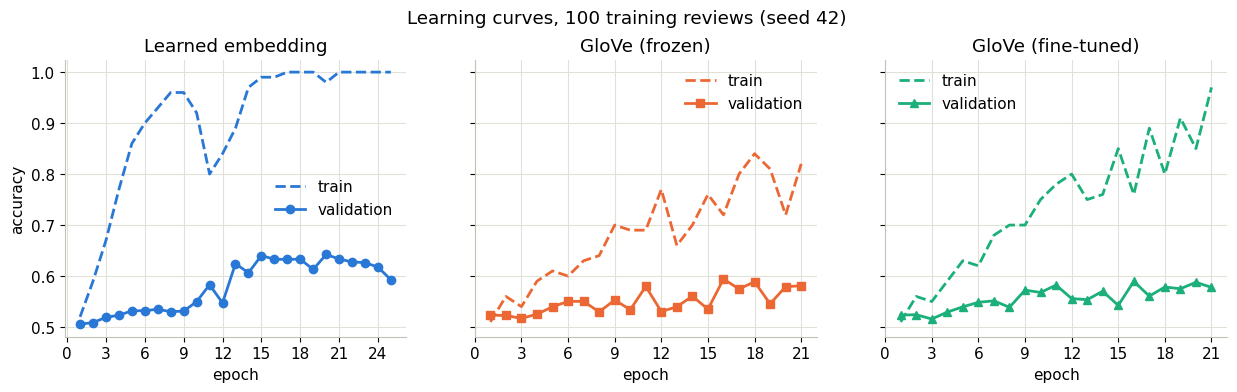

In [9]:
COLORS  = {"learned": "#2a78d6", "glove_frozen": "#eb6834", "glove_finetuned": "#1baf7a"}
MARKERS = {"learned": "o", "glove_frozen": "s", "glove_finetuned": "^"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.edgecolor": "#c3c2b7",
                     "font.size": 11})

seed0 = SEEDS_SMALL[0]
kinds_with_hist = [k for k in MODEL_KINDS if (k, seed0) in histories]
if kinds_with_hist:
    fig, axes = plt.subplots(1, len(kinds_with_hist), figsize=(5 * len(kinds_with_hist), 3.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, k in zip(axes, kinds_with_hist):
        h = histories[(k, seed0)]
        ep = np.arange(1, len(h["accuracy"]) + 1)
        ax.plot(ep, h["accuracy"], color=COLORS[k], lw=2, ls="--", label="train")
        ax.plot(ep, h["val_accuracy"], color=COLORS[k], lw=2, marker=MARKERS[k], ms=6, label="validation")
        ax.set_title(LABELS[k]); ax.set_xlabel("epoch"); ax.legend(frameon=False)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    axes[0].set_ylabel("accuracy")
    fig.suptitle(f"Learning curves, {N_TRAIN_REQUIRED} training reviews (seed {seed0})", y=1.02)
    plt.show()
else:
    print("Learning curves are only kept in memory for runs made in this session (they were loaded from the CSV).")

## 9. Varying the number of training samples: where does the learned embedding catch up?
The same comparison is repeated with 200 up to 15,000 training reviews. Validation (10,000) and test (25,000) stay fixed, so every point is directly comparable.
**This is the long cell (~30–40 min on a T4).** If Colab disconnects, re-run all cells and it continues from the saved CSV.

In [10]:
results = run_grid(TRAIN_SIZES)
print("Done.", ram())

45 runs to do (9 already saved)
[1/45] Learned embedding    n=   200 seed=42    val=0.6958 test=0.6893 (best epoch 16, 13.2s) | elapsed 0.3 min | RAM used 2.62 GB of 13.61 GB
[2/45] GloVe (frozen)       n=   200 seed=42    val=0.6153 test=0.6137 (best epoch 25, 14.3s) | elapsed 0.5 min | RAM used 2.57 GB of 13.61 GB
[3/45] GloVe (fine-tuned)   n=   200 seed=42    val=0.6166 test=0.6138 (best epoch 28, 14.7s) | elapsed 0.8 min | RAM used 2.61 GB of 13.61 GB
[4/45] Learned embedding    n=   200 seed=7     val=0.6748 test=0.6682 (best epoch 19, 13.3s) | elapsed 1.0 min | RAM used 2.57 GB of 13.61 GB
[5/45] GloVe (frozen)       n=   200 seed=7     val=0.6569 test=0.6526 (best epoch 27, 14.9s) | elapsed 1.3 min | RAM used 2.58 GB of 13.61 GB
[6/45] GloVe (fine-tuned)   n=   200 seed=7     val=0.6635 test=0.6656 (best epoch 24, 14.4s) | elapsed 1.6 min | RAM used 2.58 GB of 13.61 GB
[7/45] Learned embedding    n=   200 seed=2024  val=0.6657 test=0.6628 (best epoch 23, 13.8s) | elapsed 1.9 mi

## 10. Results summary

In [11]:
results = load_results()
results["n_train"] = results["n_train"].astype(int)
summary = (results.groupby(["n_train", "kind"])
           .agg(val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
                test_mean=("test_acc", "mean"), runs=("seed", "count"))
           .reset_index())

val_table  = summary.pivot(index="n_train", columns="kind", values="val_mean")[MODEL_KINDS]
test_table = summary.pivot(index="n_train", columns="kind", values="test_mean")[MODEL_KINDS]
table = pd.concat({"Validation accuracy": val_table.rename(columns=LABELS),
                   "Test accuracy": test_table.rename(columns=LABELS)}, axis=1)
table.index.name = "Training samples"
table[("Learned - GloVe frozen", "val gap")] = val_table["learned"] - val_table["glove_frozen"]

def highlight_best(row):
    vals = row[[("Validation accuracy", LABELS[k]) for k in MODEL_KINDS]]
    best = vals.idxmax()
    return ["font-weight: bold" if c == best else "" for c in row.index]

display(table.style.format("{:.4f}").format("{:+.4f}", subset=[("Learned - GloVe frozen", "val gap")])
        .apply(highlight_best, axis=1)
        .set_caption("Mean accuracy per training size (bold = best validation accuracy)"))
table.to_csv(os.path.join(FIG_DIR, "a4_summary_table.csv"))

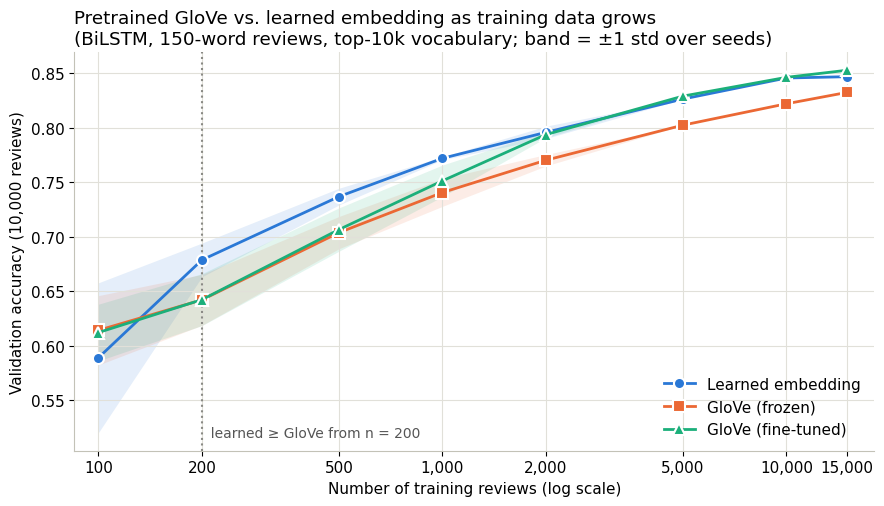

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for k in MODEL_KINDS:
    s = summary[summary.kind == k].sort_values("n_train")
    ax.plot(s.n_train, s.val_mean, color=COLORS[k], lw=2, marker=MARKERS[k], ms=8,
            markeredgecolor="white", markeredgewidth=1.5, label=LABELS[k], zorder=3)
    ax.fill_between(s.n_train, s.val_mean - s.val_std.fillna(0), s.val_mean + s.val_std.fillna(0),
                    color=COLORS[k], alpha=0.12, lw=0)

# Crossover: the smallest size from which the learned embedding stays ahead of frozen GloVe
gap = (val_table["learned"] - val_table["glove_frozen"]).sort_index()
crossover = None
for n in gap.index:
    if (gap.loc[n:] >= 0).all():
        crossover = int(n); break
if crossover is not None:
    ax.axvline(crossover, color="#8a8a85", ls=":", lw=1.5)
    ax.text(crossover, ax.get_ylim()[0] + 0.01, f"  learned ≥ GloVe from n = {crossover:,}",
            color="#555555", fontsize=10, va="bottom")

ax.set_xscale("log")
ax.set_xticks(TRAIN_SIZES); ax.set_xticklabels([f"{n:,}" for n in TRAIN_SIZES])
ax.set_xlim(TRAIN_SIZES[0] * 0.85, TRAIN_SIZES[-1] * 1.2)
ax.minorticks_off()
ax.set_xlabel("Number of training reviews (log scale)")
ax.set_ylabel("Validation accuracy (10,000 reviews)")
ax.set_title("Pretrained GloVe vs. learned embedding as training data grows\n"
             "(BiLSTM, 150-word reviews, top-10k vocabulary; band = ±1 std over seeds)", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a4_accuracy_vs_training_size.png"), dpi=150, bbox_inches="tight")
plt.show()

## 11. Conclusions (generated from your numbers)

In [13]:
r100 = val_table.loc[N_TRAIN_REQUIRED]
winner100 = r100.idxmax()
best_row = summary.loc[summary.val_mean.idxmax()]

print(f"1) With {N_TRAIN_REQUIRED} training reviews: learned embedding {r100['learned']:.3f} vs. "
      f"GloVe frozen {r100['glove_frozen']:.3f}"
      + (f" vs. GloVe fine-tuned {r100['glove_finetuned']:.3f}" if "glove_finetuned" in r100 else "")
      + f". Best: {LABELS[winner100]}.")
if crossover is not None:
    print(f"2) The learned embedding matches or beats frozen GloVe from about {crossover:,} training reviews onward "
          f"(validation gap at that size: {gap.loc[crossover]:+.3f}).")
else:
    print("2) The learned embedding never stayed ahead of frozen GloVe within the tested sizes.")
print(f"3) Best validation accuracy overall: {best_row.val_mean:.4f} "
      f"({LABELS[best_row.kind]}, {int(best_row.n_train):,} training reviews); "
      f"test accuracy {best_row.test_mean:.4f}.")

1) With 100 training reviews: learned embedding 0.589 vs. GloVe frozen 0.614 vs. GloVe fine-tuned 0.612. Best: GloVe (frozen).
2) The learned embedding matches or beats frozen GloVe from about 200 training reviews onward (validation gap at that size: +0.037).
3) Best validation accuracy overall: 0.8525 (GloVe (fine-tuned), 15,000 training reviews); test accuracy 0.8379.


### Discussion
*(Check that the wording below matches your printed numbers, and edit it if your run differs.)*

* **Very little data (100 reviews): the pretrained embedding should win.** A learned `Embedding` layer has 10,000 × 100 = 1,000,000 weights that start out random, and 100 reviews × 150 words provide at most 15,000 word occurrences to learn them from. Most vocabulary words are never seen in training, so their vectors stay random and the model memorizes the training set (training accuracy near 1.0, validation near 50%). GloVe already places words like *great/excellent* and *awful/terrible* near each other, so even a small classifier on top can generalize. This is the same idea as using a pretrained convnet when images are scarce.
* **As data grows, the learned embedding catches up and then overtakes.** With thousands of reviews the model can learn a *task-specific* space, where words are arranged by their sentiment in movie reviews and not by general co-occurrence (GloVe, for example, places *good* and *bad* close together because they appear in similar contexts). The crossover point in the chart above answers the last question of the assignment.
* **Fine-tuning GloVe** combines both: a good starting point and task adaptation. With tiny data it can overfit (the vectors drift), but with moderate data it is often the best of the three.
* **Improving performance with limited data** (MLO 4): pretrained embeddings, freezing them when data is tiny, masking the padding, dropout, early stopping on validation accuracy, and stratified sampling all help. Averaging over several seeds does not improve the model, but it is needed to *measure* it reliably at n = 100, where one run can differ from another by several points.
* **Context.** With the full 25,000 reviews (no 150-word cutoff), the course's bag-of-bigrams model reached about 90% and the BiLSTM with a learned embedding about 87–88%. Sequence models (RNNs and Transformers) need a lot of data. With small datasets, pretrained knowledge (or simpler bag-of-words models) is the better option.

## 12. Conceptual notes: attention, and RNNs vs. Transformers (MLO 2 & 3)
* **Self-attention** makes each token's representation context-aware. Every token is projected into a *query*, a *key* and a *value* (learned matrices W<sub>Q</sub>, W<sub>K</sub>, W<sub>V</sub>). A token's query is scored against every key by dot product, scaled by √d<sub>k</sub>, turned into weights with softmax, and used to take a weighted sum of the values: **softmax(QKᵀ/√d<sub>k</sub>)·V**. In *"the train left the station"*, the new vector for *station* absorbs part of *train*.
* **Multi-head attention** runs several of these in parallel with different projections (8 heads in the original paper) and combines them with W<sub>O</sub>, so different heads can learn different relationships (the same idea as depthwise separable or grouped convolutions).
* **Transformer encoder** = multi-head attention + a feed-forward network, each wrapped with a residual connection and layer normalization. Attention is order-agnostic (it sees a set), so **positional embeddings** are added to the word embeddings. The **decoder** adds masked self-attention (it cannot look at future tokens) and encoder-decoder attention (queries from the decoder, keys and values from the encoder).
* **RNNs vs. Transformers.** An RNN reads one token at a time and carries a hidden state. This is sequential (slow to train, hard to parallelize), it struggles with long-range dependencies and vanishing gradients, and in sequence-to-sequence tasks it only sees tokens 0…N when producing output N. A Transformer looks at all positions at once through attention, parallelizes well, and handles long-range context, but it needs more data. This assignment uses a BiLSTM because, with 100–15,000 short reviews, it is the more data-efficient sequence model, and the embedding question is independent of that choice.

## 13. Save outputs for GitHub (`Assignment 4` folder)
Files to upload:
1. This notebook (`File → Download → Download .ipynb`)
2. The knitted output: `File → Print → Save as PDF`, or `File → Download → Download .html` if your Colab shows that option. You can also use the optional cell below.
3. `a4_results.csv` (every run), `a4_summary_table.csv` and `a4_accuracy_vs_training_size.png` (the summary graph and table), downloaded by the next cell.

In [ ]:
try:
    from google.colab import files
    for f in ["a4_results.csv", "a4_summary_table.csv", "a4_accuracy_vs_training_size.png"]:
        p = os.path.join(FIG_DIR, f)
        if os.path.exists(p):
            files.download(p)
except ImportError:
    print("Not running in Colab. The files are in", FIG_DIR)

In [ ]:
# OPTIONAL: export this notebook to HTML. Save a copy to Drive first (File > Save a copy in Drive),
# then uncomment and set the path to that copy.
# from google.colab import drive; drive.mount('/content/drive')
# !jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Assignment4_Text_and_Sequence_Data.ipynb" --output-dir /content